
STEP 1: Locate the dataset folder
DATA_DIR = /kaggle/input
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

STEP 2: Load image paths and identify the classes
Total images in dataset : 96266
Number of classes       : 16
Classes:
   0. CCMT_unified_anthracnose
   1. CCMT_unified_bacterial blight
   2. CCMT_unified_brown spot
   3. CCMT_unified_fall armyworm
   4. CCMT_unified_green mite
   5. CCMT_unified_healthy
   6. CCMT_unified_leaf beetle
   7. CCMT_unified_leaf blight
   8. CCMT_unified_leaf curl
   9. CCMT_unified_leaf miner
  10. CCMT_unified_leaf spot
  11. CCMT_unified_mosaic
  12. CCMT_unified_red rust
  13. CCMT_unified_septoria leaf spot
  14. CCMT_unified_streak virus
  15. crop-pests-and-diseases-detection___results___files
Check passed: dataset has more than 4000 images

STEP 3: Class distribution (images per class in the full dataset)
label
CCMT_unified_anthracnose       

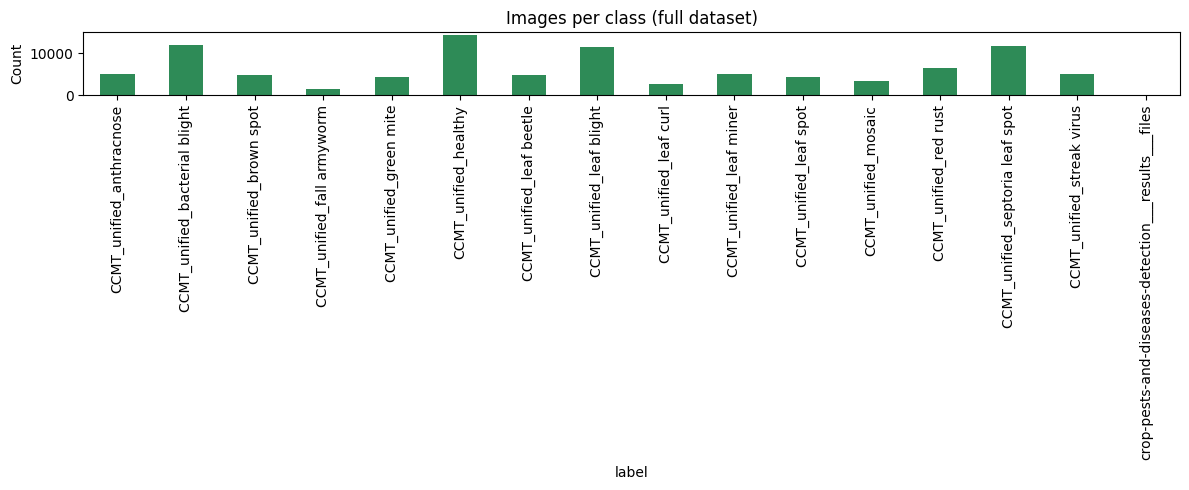


STEP 4: Size identification (dimensions and dataset size)
Dataset size on disk : 6181.0 MB
Image height min/mean/max : 333 / 400 / 400
Image width  min/mean/max : 283 / 400 / 400
All images are resized to : 224x224x3 before training

STEP 5: Show one sample image from each class


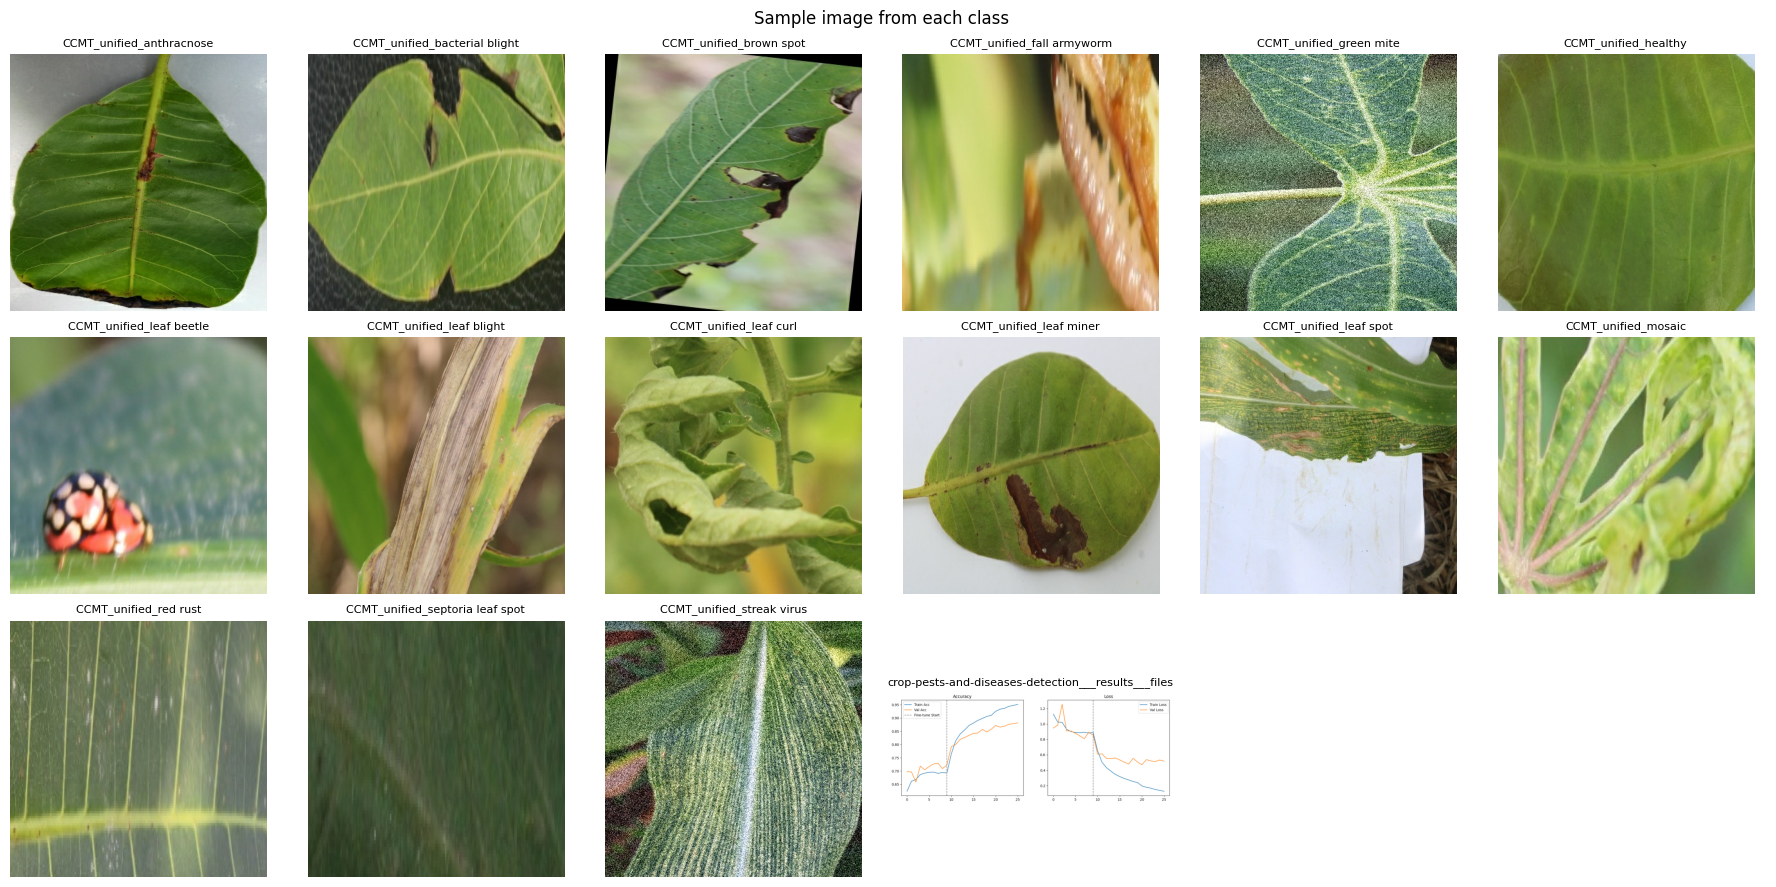


STEP 6: Split into train / validation / test (max 400 images per class per split)
Using the dataset's own train/test split
Train images      : 6003
Validation images : 5681
Test images       : 5885
Total used        : 17569

STEP 7: Augmented images (original vs augmented)
Augmentations: horizontal/vertical flip, rotation, zoom, brightness, contrast


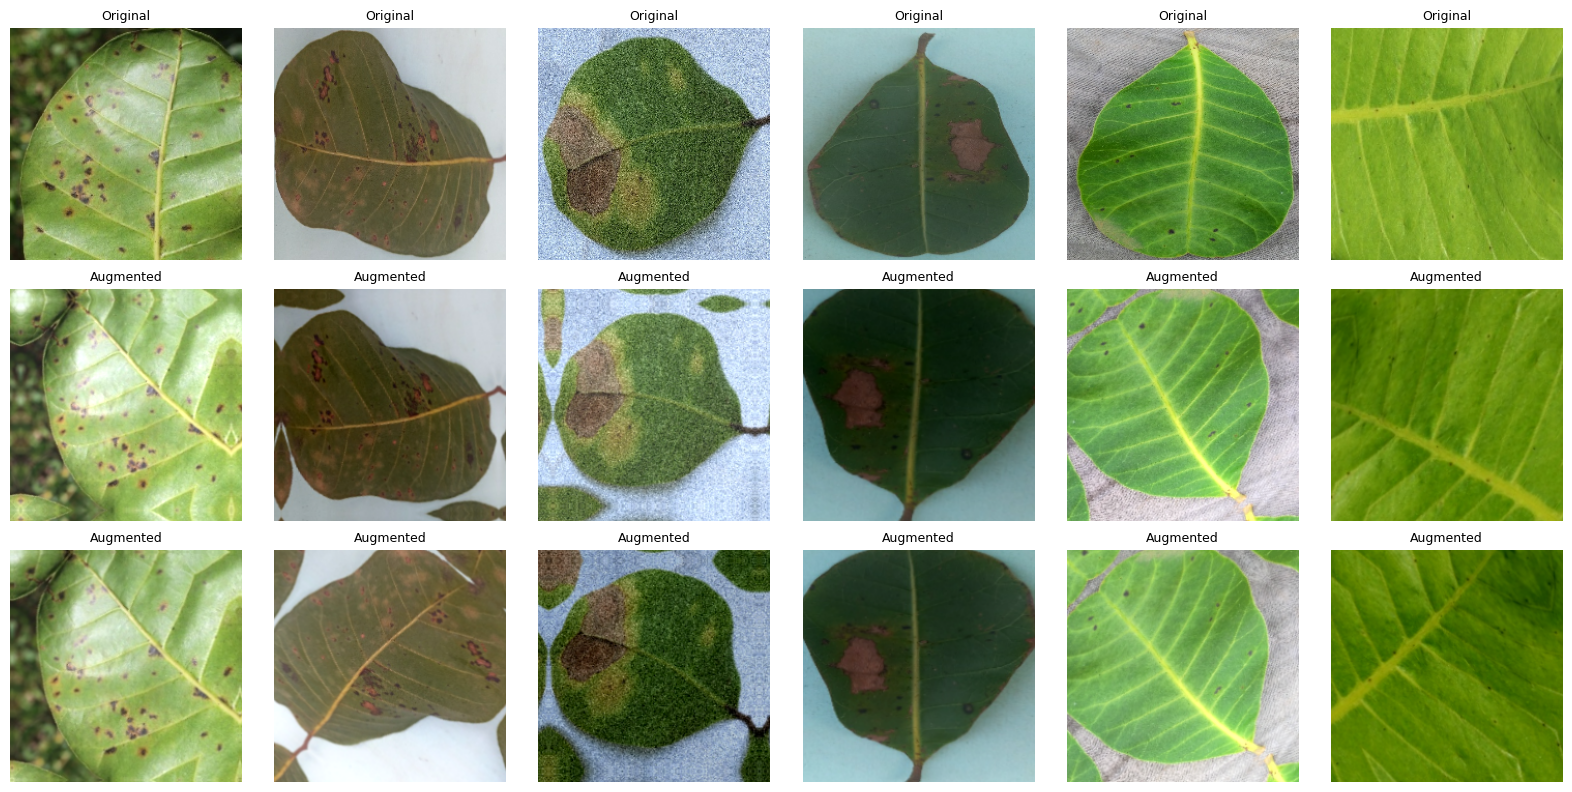


STEP 8: Define the two models: ResNet50 and MobileNetV2
Model 1: ResNet50     (ImageNet pretrained)
Model 2: MobileNetV2  (ImageNet pretrained)
Epochs per model: 3 (head) + 2 (fine-tune) = 5

STEP 9: Train and evaluate both models

----- Model 1/2: ResNet50 -----
[ResNet50] Stage 1: training classifier head (3 epochs)
Epoch 1/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 106s 531ms/step - accuracy: 0.5009 - loss: 1.5668 - val_accuracy: 0.6594 - val_loss: 0.9881
Epoch 2/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 49s 262ms/step - accuracy: 0.6695 - loss: 0.9897 - val_accuracy: 0.7280 - val_loss: 0.7928
Epoch 3/3
188/188 ━━━━━━━━━━━━━━━━━━━━ 48s 258ms/step - accuracy: 0.7106 - loss: 0.8660 - val_accuracy: 0.7050 - val_loss: 0.8912
[ResNet50] Stage 2: fine-tuning last 30 layers (2 epochs)
Epoch 1/2
188/188 ━━━━━━━━━━━━━━━━━━━━ 67s 311ms/step - accuracy: 0.7495 - loss: 0.7331 - val_accuracy: 0.7643 - val_loss: 0.6796
Epoch 2/2
188/188 ━━━━━━━━━━━━━━━━━━━━ 56s 299ms/step - accuracy: 0.7758 - loss: 0.6534 - val_accura

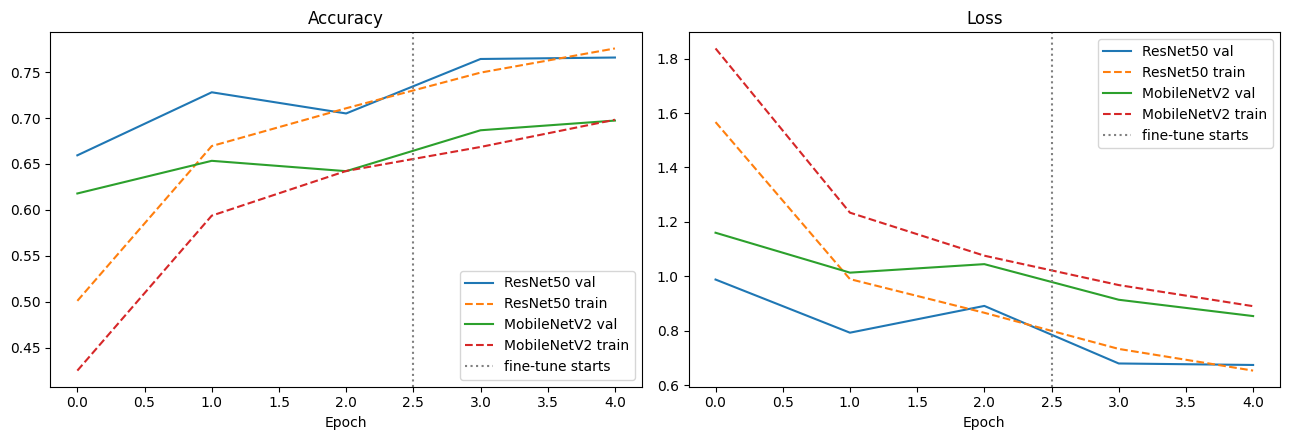


STEP 11: Confusion matrices


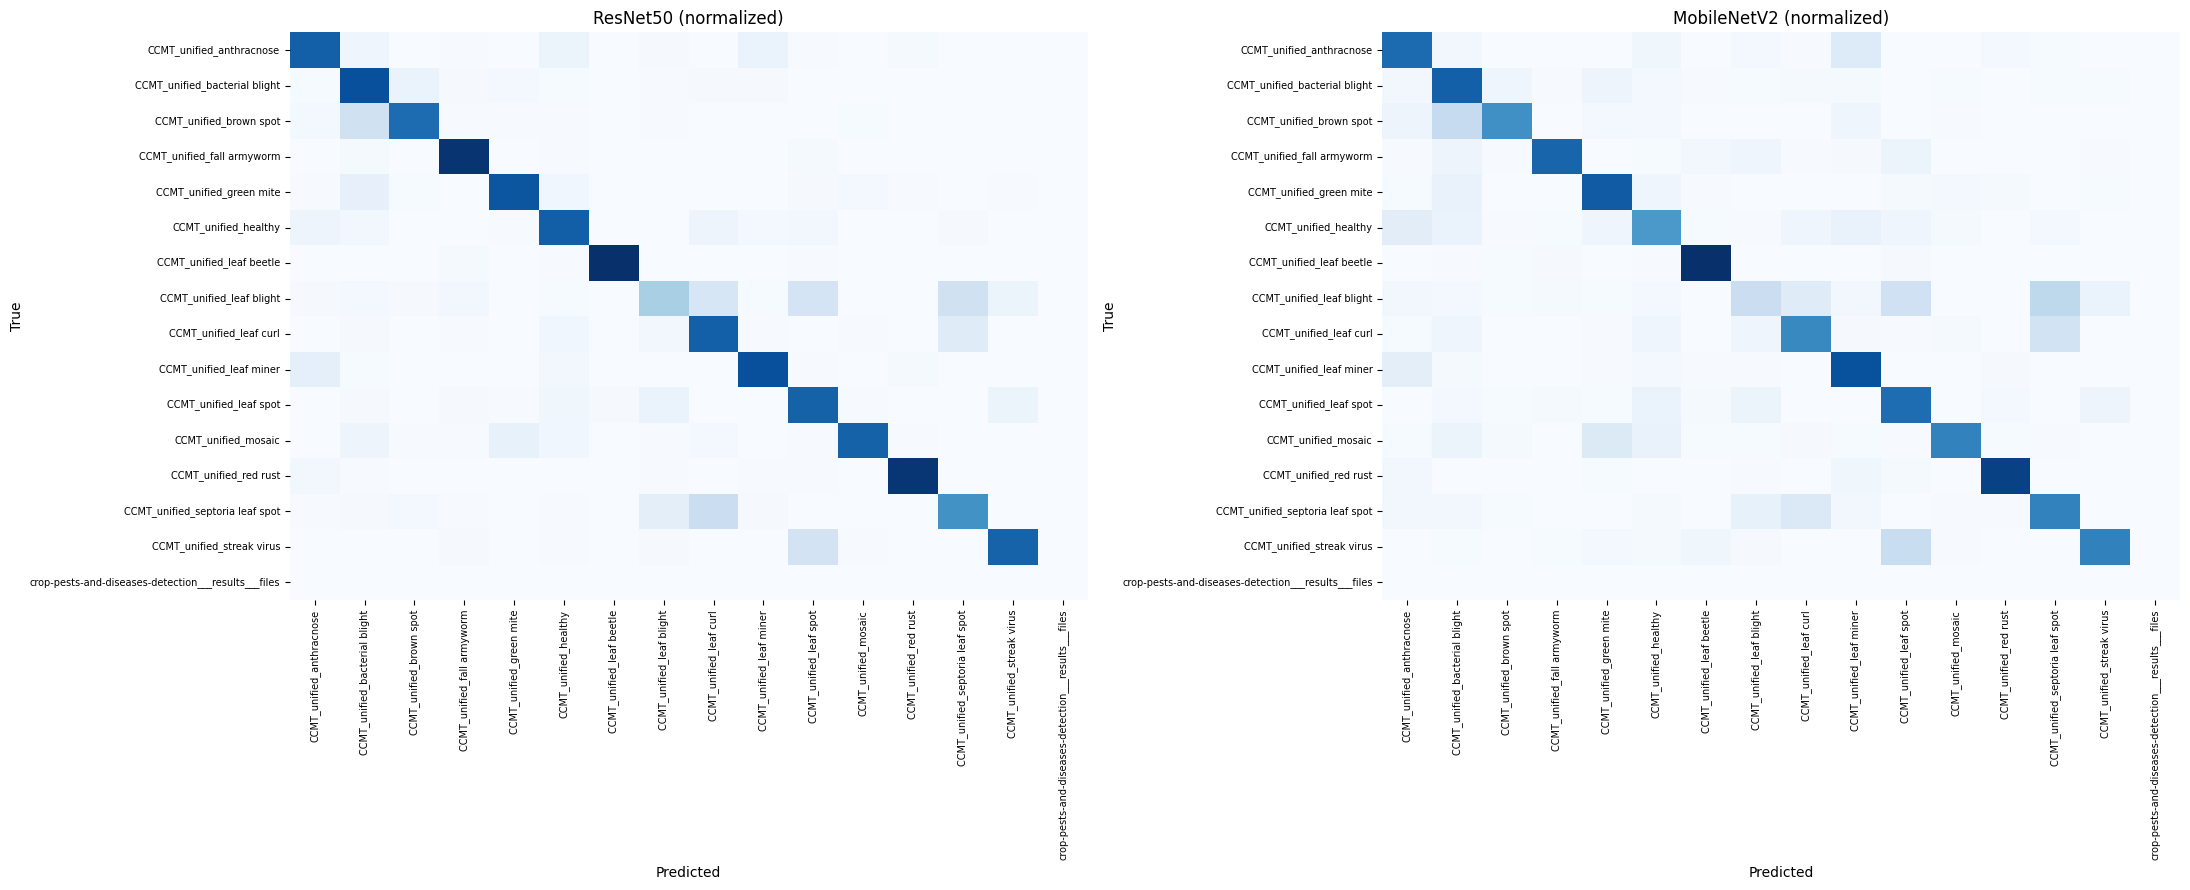


STEP 12: Comparison chart of the two models
             Accuracy  Precision  Recall      F1  Train time (min)  Inference (ms/img)  Parameters (M)
ResNet50       0.7772     0.7825  0.7772  0.7743            5.4427             31.0580         23.6205
MobileNetV2    0.6984     0.7059  0.6984  0.6932            1.9143              2.0092          2.2785


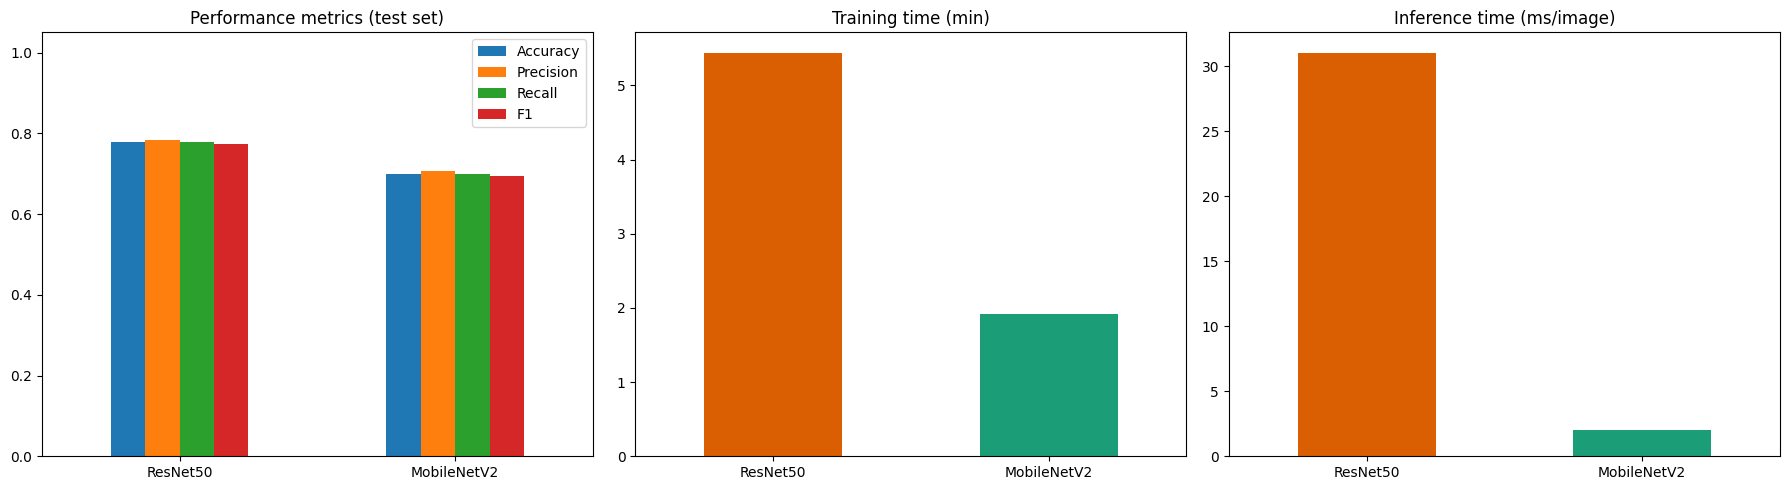


Best model by test accuracy: ResNet50 (0.7772)

STEP 13: Unique dataset justification and final summary

Dataset      : CCMT - Crop Pest and Disease Detection (Ghana, 2023)
Total images : 96266   |  Classes: 16
Used         : 6003 train / 5681 val / 5885 test  (max 400 per class)
Models       : ResNet50, MobileNetV2  (5 epochs each)
Best model   : ResNet50

Why this dataset is unique:
- Published 2023 (after 2020), from local farms in Ghana.
- 4 crops (cashew, cassava, maize, tomato), 22 pest/disease/healthy classes.
- Real field images, unlike lab-style PlantVillage; much less commonly used.

All plots and models saved in: results


In [5]:
# Lab Test: Crop Pest & Disease Classification (CCMT dataset) - ResNet50 vs MobileNetV2
# Run on Kaggle: Add Input -> "Crop Pest and Disease Dataset", Accelerator -> GPU.
   

# ============================== IMPORTS ==============================
import os, time, random, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pre
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobile_pre
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support, accuracy_score


def step(n, title):
    print("\n" + "=" * 70)
    print(f"STEP {n}: {title}")
    print("=" * 70)


# ============================== SETTINGS ==============================
LABEL_DEPTH = 2          # 2 -> "Maize_fall_armyworm" (22 distinct classes); 1 -> "fall_armyworm"
MAX_PER_CLASS = 400      # images per class (applied to train, val and test separately); None = all
EPOCHS_HEAD = 3          # stage 1: train classifier head
EPOCHS_FINE = 2          # stage 2: fine-tune top layers  -> 3 + 2 = 5 epochs per model
UNFREEZE_LAST = 30
IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42
OUT = "results"
os.makedirs(OUT, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ============================== STEP 1 ==============================
step(1, "Locate the dataset folder")
DATA_DIR = "/kaggle/input"
for r, d, _ in os.walk("/kaggle/input"):
    if any(x.lower() == "cashew" for x in d):
        DATA_DIR = r
        break
print("DATA_DIR =", DATA_DIR)
print("GPU available:", tf.config.list_physical_devices("GPU"))

# ============================== STEP 2 ==============================
step(2, "Load image paths and identify the classes")
exts = {".jpg", ".jpeg", ".png"}
SPLIT_NAMES = {"train_set", "test_set", "train", "test", "val", "valid", "validation"}
root = pathlib.Path(DATA_DIR)
rows = []
for p in root.rglob("*"):
    if p.suffix.lower() in exts:
        parts = list(p.parent.relative_to(root).parts)
        split = next((s.lower() for s in parts if s.lower() in SPLIT_NAMES), None)
        clean = [s for s in parts if s.lower() not in SPLIT_NAMES]
        rows.append((str(p), "_".join(clean[-LABEL_DEPTH:]), split))
df = pd.DataFrame(rows, columns=["path", "label", "split"])
assert len(df) > 0, "No images found. Check DATA_DIR."

classes = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df.label.map(class_to_idx)

print(f"Total images in dataset : {len(df)}")
print(f"Number of classes       : {len(classes)}")
print("Classes:")
for i, c in enumerate(classes):
    print(f"  {i:2d}. {c}")
assert len(df) > 4000, "Dataset must have more than 4000 images"
print("Check passed: dataset has more than 4000 images")

# ============================== STEP 3 ==============================
step(3, "Class distribution (images per class in the full dataset)")
counts = df.label.value_counts().sort_index()
print(counts.to_string())
plt.figure(figsize=(12, 5))
counts.plot(kind="bar", color="seagreen")
plt.title("Images per class (full dataset)"); plt.ylabel("Count"); plt.tight_layout()
plt.savefig(f"{OUT}/class_distribution.png", dpi=150); plt.show()

# ============================== STEP 4 ==============================
step(4, "Size identification (dimensions and dataset size)")
total_mb = sum(os.path.getsize(p) for p in df.path) / (1024 * 1024)
sample = df.sample(min(300, len(df)), random_state=SEED)
dims = []
for p in sample.path:
    img = tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
    dims.append(img.shape[:2])
dims = np.array(dims)
print(f"Dataset size on disk : {total_mb:.1f} MB")
print(f"Image height min/mean/max : {dims[:,0].min()} / {dims[:,0].mean():.0f} / {dims[:,0].max()}")
print(f"Image width  min/mean/max : {dims[:,1].min()} / {dims[:,1].mean():.0f} / {dims[:,1].max()}")
print(f"All images are resized to : {IMG_SIZE[0]}x{IMG_SIZE[1]}x3 before training")

# ============================== STEP 5 ==============================
step(5, "Show one sample image from each class")
n = len(classes); cols = 6; rws = int(np.ceil(n / cols))
fig, axes = plt.subplots(rws, cols, figsize=(3 * cols, 3 * rws))
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), classes):
    p = df[df.label == c].sample(1, random_state=SEED).path.iloc[0]
    ax.imshow(tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False).numpy())
    ax.set_title(c, fontsize=8)
plt.suptitle("Sample image from each class"); plt.tight_layout()
plt.savefig(f"{OUT}/class_samples.png", dpi=150); plt.show()

# ============================== STEP 6 ==============================
step(6, f"Split into train / validation / test (max {MAX_PER_CLASS} images per class per split)")
if df.split.isin(["test_set", "test"]).any():
    is_test = df.split.isin(["test_set", "test"])
    trainval_df, test_df = df[~is_test], df[is_test]
    print("Using the dataset's own train/test split")
else:
    trainval_df, test_df = train_test_split(df, test_size=0.15, stratify=df.y, random_state=SEED)
    print("No predefined split found: using a random stratified split")
train_df, val_df = train_test_split(trainval_df, test_size=0.15, stratify=trainval_df.y, random_state=SEED)


def cap(d):
    if not MAX_PER_CLASS:
        return d
    return pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED) for _, g in d.groupby("y")])


train_df, val_df, test_df = cap(train_df), cap(val_df), cap(test_df)
print(f"Train images      : {len(train_df)}")
print(f"Validation images : {len(val_df)}")
print(f"Test images       : {len(test_df)}")
print(f"Total used        : {len(train_df) + len(val_df) + len(test_df)}")


def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32), y


def make_ds(d, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)


train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df, False), make_ds(test_df, False)

# ============================== STEP 7 ==============================
step(7, "Augmented images (original vs augmented)")
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")
print("Augmentations: horizontal/vertical flip, rotation, zoom, brightness, contrast")

imgs, _ = next(iter(val_ds))
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for i in range(6):
    axes[0, i].imshow(imgs[i].numpy().astype("uint8")); axes[0, i].set_title("Original", fontsize=9)
    for r_ in (1, 2):
        aug_img = augment(tf.expand_dims(imgs[i], 0), training=True)[0]
        axes[r_, i].imshow(tf.clip_by_value(aug_img, 0, 255).numpy().astype("uint8"))
        axes[r_, i].set_title("Augmented", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/augmentation_preview.png", dpi=150); plt.show()

# ============================== STEP 8 ==============================
step(8, "Define the two models: ResNet50 and MobileNetV2")


def build_model(name):
    if name == "ResNet50":
        base = ResNet50(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
        pre = resnet_pre
    else:
        base = MobileNetV2(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
        pre = mobile_pre
    base.trainable = False
    inp = layers.Input(IMG_SIZE + (3,))
    x = augment(inp)
    x = layers.Lambda(pre, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(len(classes), activation="softmax")(x)
    return models.Model(inp, out, name=name), base


def compile_model(m, lr):
    m.compile(tf.keras.optimizers.Adam(lr), "sparse_categorical_crossentropy", metrics=["accuracy"])


print("Model 1: ResNet50     (ImageNet pretrained)")
print("Model 2: MobileNetV2  (ImageNet pretrained)")
print(f"Epochs per model: {EPOCHS_HEAD} (head) + {EPOCHS_FINE} (fine-tune) = {EPOCHS_HEAD + EPOCHS_FINE}")

# ============================== STEP 9 ==============================
step(9, "Train and evaluate both models")
results, histories, preds = {}, {}, {}
y_true = test_df.y.values

for k, name in enumerate(["ResNet50", "MobileNetV2"], start=1):
    print(f"\n----- Model {k}/2: {name} -----")
    model, base = build_model(name)

    start = time.time()
    print(f"[{name}] Stage 1: training classifier head ({EPOCHS_HEAD} epochs)")
    compile_model(model, 1e-3)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD)

    print(f"[{name}] Stage 2: fine-tuning last {UNFREEZE_LAST} layers ({EPOCHS_FINE} epochs)")
    base.trainable = True
    for layer in base.layers[:-UNFREEZE_LAST]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    compile_model(model, 1e-5)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE)
    train_time = time.time() - start

    histories[name] = {key: h1.history[key] + h2.history[key] for key in h1.history}

    print(f"[{name}] Evaluating on the test set")
    t0 = time.time()
    prob = model.predict(test_ds)
    infer_ms = (time.time() - t0) / len(test_df) * 1000
    y_pred = prob.argmax(1)
    preds[name] = y_pred

    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": p, "Recall": r, "F1": f1,
        "Train time (min)": train_time / 60,
        "Inference (ms/img)": infer_ms,
        "Parameters (M)": model.count_params() / 1e6,
    }
    print(f"[{name}] Test accuracy: {results[name]['Accuracy']:.4f} | Training time: {train_time/60:.1f} min")
    print(classification_report(y_true, y_pred, labels=range(len(classes)), target_names=classes, zero_division=0))
    model.save(f"{OUT}/{name}.keras")

# ============================== STEP 10 ==============================
step(10, "Training curves (accuracy and loss)")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    axes[0].plot(h["val_accuracy"], label=f"{name} val")
    axes[0].plot(h["accuracy"], "--", label=f"{name} train")
    axes[1].plot(h["val_loss"], label=f"{name} val")
    axes[1].plot(h["loss"], "--", label=f"{name} train")
for ax, t in zip(axes, ["Accuracy", "Loss"]):
    ax.axvline(EPOCHS_HEAD - 0.5, color="gray", ls=":", label="fine-tune starts")
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=150); plt.show()

# ============================== STEP 11 ==============================
step(11, "Confusion matrices")
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, name in zip(axes, preds):
    cm = confusion_matrix(y_true, preds[name], labels=range(len(classes)), normalize="true")
    sns.heatmap(cm, ax=ax, cmap="Blues", xticklabels=classes, yticklabels=classes, cbar=False)
    ax.set_title(f"{name} (normalized)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=150); plt.show()

# ============================== STEP 12 ==============================
step(12, "Comparison chart of the two models")
res = pd.DataFrame(results).T
print(res.round(4).to_string())
res.round(4).to_csv(f"{OUT}/model_comparison.csv")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
res[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ax=axes[0], ylim=(0, 1.05))
axes[0].set_title("Performance metrics (test set)"); axes[0].tick_params(axis="x", rotation=0)
res["Train time (min)"].plot(kind="bar", ax=axes[1], color=["#d95f02", "#1b9e77"])
axes[1].set_title("Training time (min)"); axes[1].tick_params(axis="x", rotation=0)
res["Inference (ms/img)"].plot(kind="bar", ax=axes[2], color=["#d95f02", "#1b9e77"])
axes[2].set_title("Inference time (ms/image)"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(f"{OUT}/model_comparison.png", dpi=150); plt.show()

best = res.Accuracy.idxmax()
print(f"\nBest model by test accuracy: {best} ({res.loc[best, 'Accuracy']:.4f})")

# ============================== STEP 13 ==============================
step(13, "Unique dataset justification and final summary")
print(f"""
Dataset      : CCMT - Crop Pest and Disease Detection (Ghana, 2023)
Total images : {len(df)}   |  Classes: {len(classes)}
Used         : {len(train_df)} train / {len(val_df)} val / {len(test_df)} test  (max {MAX_PER_CLASS} per class)
Models       : ResNet50, MobileNetV2  ({EPOCHS_HEAD + EPOCHS_FINE} epochs each)
Best model   : {best}

Why this dataset is unique:
- Published 2023 (after 2020), from local farms in Ghana.
- 4 crops (cashew, cassava, maize, tomato), 22 pest/disease/healthy classes.
- Real field images, unlike lab-style PlantVillage; much less commonly used.
""")
print("All plots and models saved in:", OUT)